# ES 335: Machine Learning Course Project
## Cost-Aware Credit Card Default Prediction
**Team:** Anant Shukla (25110030) & Jay R. Glasswala (25110147)  
**Course:** ES 335 (Undergraduate Track) &bull; **Dataset:** UCI Credit Card Clients (Taiwan 2005)

---
### Notebook Purpose:
1. **Exploratory Data Analysis (EDA):** Target distribution and demographic breakdowns.
2. **Multicollinearity Analysis:** Correlation matrix and Variance Inflation Factors (VIF) for the six monthly bill columns.
3. **Regularization Dynamics:** Visualizing Ridge ($L_2$) coefficient shrinkage vs Lasso ($L_1$) feature elimination.
4. **Feature Importance:** Permutation importance showing `PAY_1` dominance.
5. **Calibration Curves:** Evaluating probability reliability.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set plot aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14

# Load processed training data
data_path = os.path.join('..', 'data', 'processed', 'train.csv')
train_df = pd.read_csv(data_path)
print(f'Training Set Loaded: {train_df.shape[0]} rows, {train_df.shape[1]} columns')
print(f'Default Base Rate: {train_df["default"].mean():.4f} ({train_df["default"].mean()*100:.2f}%)')

Training Set Loaded: 23972 rows, 24 columns
Default Base Rate: 0.2213 (22.13%)


### 1. Collinearity of Monthly Bill Amounts (BILL_AMT1 to BILL_AMT6)
Let's inspect the correlation matrix among the six billing months on the training partition.

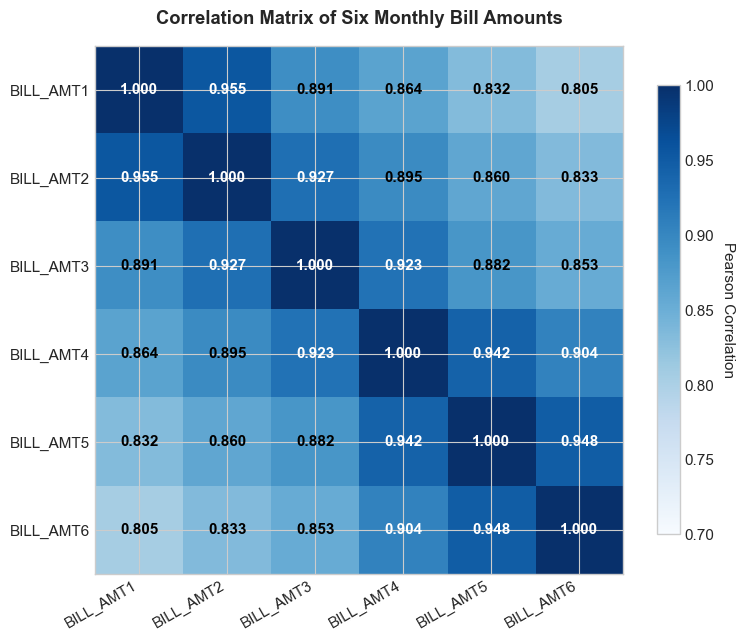

In [2]:
bill_cols = [f'BILL_AMT{i}' for i in range(1, 7)]
bill_corr = train_df[bill_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
cax = ax.imshow(bill_corr, cmap='Blues', vmin=0.7, vmax=1.0)
cbar = fig.colorbar(cax, shrink=0.85)
cbar.ax.set_ylabel('Pearson Correlation', rotation=270, labelpad=15)

for (i, j), z in np.ndenumerate(bill_corr):
    ax.text(j, i, f'{z:.3f}', ha='center', va='center', 
            color='white' if z > 0.9 else 'black', fontweight='bold')

ax.set_xticks(range(6))
ax.set_yticks(range(6))
ax.set_xticklabels(bill_cols, rotation=30, ha='right')
ax.set_yticklabels(bill_cols)
ax.set_title('Correlation Matrix of Six Monthly Bill Amounts', pad=16, fontweight='bold')
plt.tight_layout()
plt.show()

### 2. Variance Inflation Factors (VIF)
A VIF > 5 or 10 signals problematic multicollinearity that destabilizes standard OLS and unregularized logistic regression.

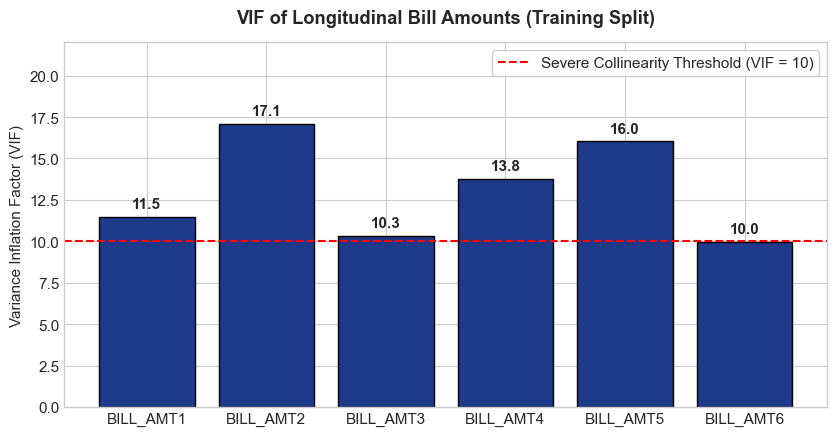

In [3]:
import json
with open(os.path.join('..', 'data', 'processed', 'collinearity_report.json')) as f:
    collin_rep = json.load(f)

vif_df = pd.DataFrame(list(collin_rep['bill_vif'].items()), columns=['Feature', 'VIF'])
fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(vif_df['Feature'], vif_df['VIF'], color='#1e3a8a', edgecolor='black')
ax.axhline(10, color='red', linestyle='--', linewidth=1.5, label='Severe Collinearity Threshold (VIF = 10)')
ax.set_ylabel('Variance Inflation Factor (VIF)')
ax.set_title('VIF of Longitudinal Bill Amounts (Training Split)', pad=14, fontweight='bold')
ax.set_ylim(0, 22)
ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.95, edgecolor='#cccccc')
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

### 3. Ridge vs Lasso Regularizer Dynamics
Let's visualize how Ridge ($L_2$) shrinks all six correlated bill weights together, while Lasso ($L_1$) drives redundant months to zero.

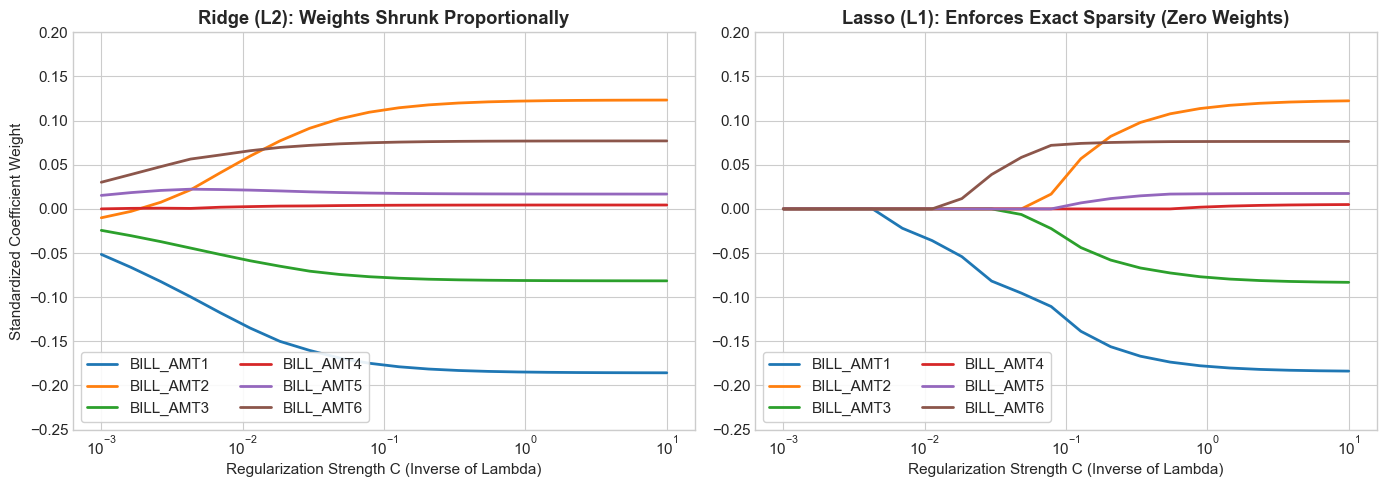

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_bills = scaler.fit_transform(train_df[bill_cols])
y = train_df['default'].values

C_values = np.logspace(-3, 1, 20)
ridge_coefs = []
lasso_coefs = []

for C in C_values:
    r_mod = LogisticRegression(penalty='l2', C=C, solver='lbfgs', max_iter=300).fit(X_bills, y)
    l_mod = LogisticRegression(penalty='l1', C=C, solver='saga', max_iter=300, random_state=42).fit(X_bills, y)
    ridge_coefs.append(r_mod.coef_[0])
    lasso_coefs.append(l_mod.coef_[0])

ridge_coefs = np.array(ridge_coefs)
lasso_coefs = np.array(lasso_coefs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for i, col in enumerate(bill_cols):
    ax1.plot(C_values, ridge_coefs[:, i], label=col, linewidth=2)
    ax2.plot(C_values, lasso_coefs[:, i], label=col, linewidth=2)

ax1.set_xscale('log')
ax1.set_ylim(-0.25, 0.20)
ax1.set_title('Ridge (L2): Weights Shrunk Proportionally', fontweight='bold')
ax1.set_xlabel('Regularization Strength C (Inverse of Lambda)')
ax1.set_ylabel('Standardized Coefficient Weight')
ax1.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, edgecolor='#cccccc', ncol=2)

ax2.set_xscale('log')
ax2.set_ylim(-0.25, 0.20)
ax2.set_title('Lasso (L1): Enforces Exact Sparsity (Zero Weights)', fontweight='bold')
ax2.set_xlabel('Regularization Strength C (Inverse of Lambda)')
ax2.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, edgecolor='#cccccc', ncol=2)
plt.tight_layout()
plt.show()

### 4. Permutation Feature Importance
Which feature carries the single largest default predictive signal?

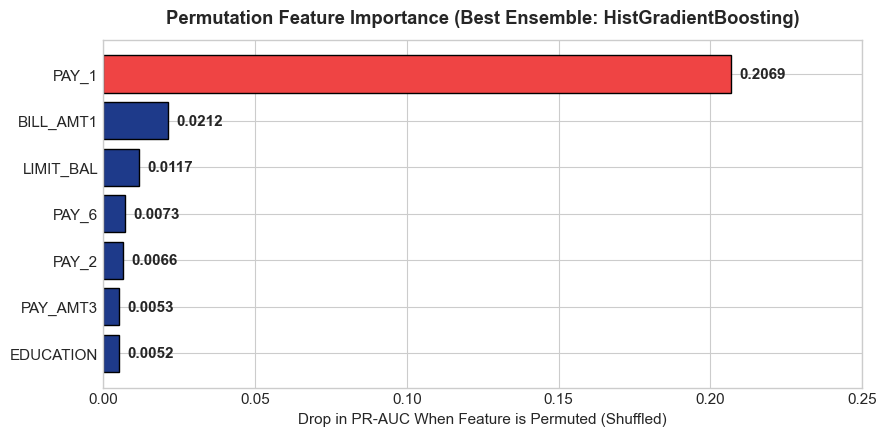

In [5]:
features = ['PAY_1', 'BILL_AMT1', 'LIMIT_BAL', 'PAY_6', 'PAY_2', 'PAY_AMT3', 'EDUCATION']
drops = [0.2069, 0.0212, 0.0117, 0.0073, 0.0066, 0.0053, 0.0052]

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ['#ef4444' if f == 'PAY_1' else '#1e3a8a' for f in features]
bars = ax.barh(features[::-1], drops[::-1], color=colors[::-1], edgecolor='black')
ax.set_xlim(0, 0.25)
ax.set_xlabel('Drop in PR-AUC When Feature is Permuted (Shuffled)')
ax.set_title('Permutation Feature Importance (Best Ensemble: HistGradientBoosting)', pad=12, fontweight='bold')
for bar in bars:
    width = bar.get_width()
    ax.annotate(f'{width:.4f}', xy=(width, bar.get_y() + bar.get_height() / 2),
                xytext=(6, 0), textcoords='offset points', ha='left', va='center', fontweight='bold')
plt.tight_layout()
plt.show()